# Baseline Multivariate Linear Regression — Hourly Energy Consumption
Predicts `energy_kwh` from weather parameters using a simple MLR model.

In [1]:
# =============================================================================
# 1. IMPORTS
# =============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print('All libraries imported successfully.')

All libraries imported successfully.


In [2]:
# =============================================================================
# 2. FILE PATHS
# =============================================================================
ENERGY_PATH  = '../data/interim/hourly_energy.csv'
WEATHER_PATH = '../data/interim/weather_hourly.csv'

# =============================================================================
# 3. LOAD DATA
# =============================================================================
energy_df  = pd.read_csv(ENERGY_PATH)
weather_df = pd.read_csv(WEATHER_PATH)

print('Energy  shape :', energy_df.shape)
print('Weather shape :', weather_df.shape)
print('Energy  columns :', energy_df.columns.tolist())
print('Weather columns :', weather_df.columns.tolist())

Energy  shape : (2572, 2)
Weather shape : (6388, 22)
Energy  columns : ['cleaned bucket', 'energy_kwh.1']
Weather columns : ['timestamp', 'temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in']


In [3]:
# =============================================================================
# 4. CONVERT TIMESTAMPS TO DATETIME
#    energy_df  -> timestamp column is 'cleaned bucket'
#    weather_df -> timestamp column is 'timestamp'
# =============================================================================
energy_df['cleaned bucket'] = pd.to_datetime(energy_df['cleaned bucket'])
weather_df['timestamp']     = pd.to_datetime(weather_df['timestamp'])

print('Energy  timestamp dtype :', energy_df['cleaned bucket'].dtype)
print('Weather timestamp dtype :', weather_df['timestamp'].dtype)

Energy  timestamp dtype : datetime64[ns]
Weather timestamp dtype : datetime64[ns]


In [4]:
# =============================================================================
# 5. MERGE ON TIMESTAMP — INNER JOIN
# =============================================================================
merged_df = pd.merge(
    energy_df,
    weather_df,
    left_on='cleaned bucket',
    right_on='timestamp',
    how='inner'
)

print('Merged shape:', merged_df.shape)
merged_df.head(3)

Merged shape: (2214, 24)


,cleaned bucket,energy_kwh.1,timestamp,temp_hi,bar,dew_in,temp_in,pt_dew,index_thsw,index_uv,...,density_in_air,rain,run_wind,emc_in,rate_rain,out_temp,speed_hi,speed_wind,tx_wind,hum_in
0,2025-09-20 05:00:00,276.50,2025-09-20 05:00:00,30.375,29.8315,17.625,23.775,26.550,44.775,4.325,...,0.072550,0.0,1.6100,12.650,0.0,30.275,17.3,6.425,1.0,68.50
1,2025-09-20 06:00:00,269.25,2025-09-20 06:00:00,30.800,29.8005,21.400,25.675,25.975,43.625,3.700,...,0.071625,0.0,2.7175,15.035,0.0,30.700,19.3,10.900,1.0,77.25
2,2025-09-20 07:00:00,286.75,2025-09-20 07:00:00,30.975,29.7730,22.375,26.600,26.025,42.600,2.650,...,0.071225,0.0,2.6125,15.175,0.0,30.900,17.7,10.500,1.0,77.75


In [5]:
# =============================================================================
# 6. DROP REMAINING NULL VALUES
#    (speed_hi has 7 nulls after merge — they are dropped here)
# =============================================================================
null_summary = merged_df.isnull().sum()
print('Columns with nulls before drop:')
print(null_summary[null_summary > 0])

merged_df.dropna(inplace=True)
merged_df.reset_index(drop=True, inplace=True)

print(f'\nShape after dropping nulls: {merged_df.shape}')

Columns with nulls before drop:
speed_hi    7
dtype: int64

Shape after dropping nulls: (2207, 24)


In [6]:
# =============================================================================
# 7. DEFINE FEATURES (X) AND TARGET (y)
#    Target  : energy_kwh.1
#    Features: all numerical weather columns
# =============================================================================
TARGET_COL     = 'energy_kwh.1'
TIMESTAMP_COLS = ['cleaned bucket', 'timestamp']

feature_cols = [
    col for col in merged_df.select_dtypes(include=[np.number]).columns
    if col not in TIMESTAMP_COLS + [TARGET_COL]
]

X = merged_df[feature_cols]
y = merged_df[TARGET_COL]

print(f'Target   : {TARGET_COL}')
print(f'Features ({len(feature_cols)}): {feature_cols}')
print(f'X shape  : {X.shape}  |  y shape : {y.shape}')

Target   : energy_kwh.1
Features (21): ['temp_hi', 'bar', 'dew_in', 'temp_in', 'pt_dew', 'index_thsw', 'index_uv', 'hum_out', 'dose_uv', 'dd_heat', 'temp_low', 'density_in_air', 'rain', 'run_wind', 'emc_in', 'rate_rain', 'out_temp', 'speed_hi', 'speed_wind', 'tx_wind', 'hum_in']
X shape  : (2207, 21)  |  y shape : (2207,)


In [7]:
# =============================================================================
# 8. TRAIN-TEST SPLIT  (80 % train / 20 % test)
# =============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f'Train rows : {X_train.shape[0]}')
print(f'Test  rows : {X_test.shape[0]}')

Train rows : 1765
Test  rows : 442


In [8]:
# =============================================================================
# 9. FEATURE STANDARDISATION
#    Fit ONLY on training data — transform both train and test.
# =============================================================================
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Scaling complete.')
print('Train feature means (should be ~0):', X_train_scaled.mean(axis=0).round(4))

Scaling complete.
Train feature means (should be ~0): [ 0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0. -0.  0. -0. -0.  0. -0.  0.
 -0.  0.  0.]


In [9]:
# =============================================================================
# 10. TRAIN BASELINE LINEAR REGRESSION MODEL
# =============================================================================
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print('Model training complete.')

Model training complete.


In [10]:
# =============================================================================
# 11. PREDICTIONS & EVALUATION METRICS
# =============================================================================
y_train_pred = model.predict(X_train_scaled)
y_test_pred  = model.predict(X_test_scaled)

train_r2  = r2_score(y_train, y_train_pred)
test_r2   = r2_score(y_test,  y_test_pred)
test_mae  = mean_absolute_error(y_test,  y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print('=' * 44)
print(f'  R\u00b2   \u2014 Train  : {train_r2:.4f}')
print(f'  R\u00b2   \u2014 Test   : {test_r2:.4f}')
print(f'  MAE  \u2014 Test   : {test_mae:.4f} kWh')
print(f'  RMSE \u2014 Test   : {test_rmse:.4f} kWh')
print('=' * 44)

  R²   — Train  : 0.0272
  R²   — Test   : 0.0031
  MAE  — Test   : 222.5323 kWh
  RMSE — Test   : 1643.0253 kWh


In [11]:
# =============================================================================
# 12. MODEL COEFFICIENTS
# =============================================================================
coeff_df = (
    pd.DataFrame({
        'Feature'    : feature_cols,
        'Coefficient': model.coef_
    })
    .sort_values('Coefficient', ascending=False)
    .reset_index(drop=True)
)

print(f'Intercept : {model.intercept_:.4f}\n')
print('Feature Coefficients (sorted high \u2192 low):')
print(coeff_df.to_string(index=False))

Intercept : 234.7773

Feature Coefficients (sorted high → low):
       Feature   Coefficient
      out_temp  5.738391e+02
       hum_out  3.662211e+02
      temp_low  3.215561e+02
        dew_in  1.846611e+02
      index_uv  1.154526e+02
           bar  5.846851e+01
      speed_hi  2.844746e+01
     rate_rain  5.869217e+00
      run_wind  3.625050e+00
       dd_heat  1.875833e-12
       tx_wind  0.000000e+00
    index_thsw -1.621861e+00
          rain -7.801051e+00
       temp_hi -8.461921e+00
    speed_wind -1.618411e+01
        emc_in -3.336016e+01
       dose_uv -4.487828e+01
density_in_air -5.616410e+01
        hum_in -8.386699e+01
       temp_in -5.610280e+02
        pt_dew -5.938870e+02


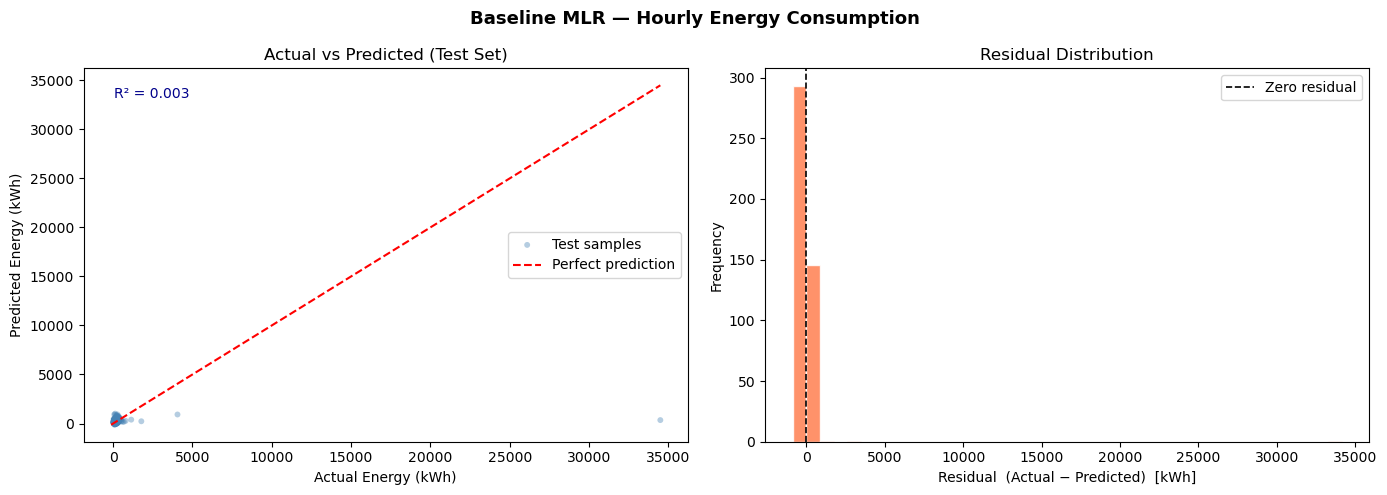

Plots saved to mlr_plots.png


In [12]:
# =============================================================================
# 13. PLOTS
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Baseline MLR \u2014 Hourly Energy Consumption', fontsize=13, fontweight='bold')

# ── Plot A : Actual vs Predicted ─────────────────────────────────────────────
ax1 = axes[0]
ax1.scatter(y_test, y_test_pred,
            alpha=0.4, s=18, color='steelblue', edgecolors='none',
            label='Test samples')
lim_min = min(y_test.min(), y_test_pred.min())
lim_max = max(y_test.max(), y_test_pred.max())
ax1.plot([lim_min, lim_max], [lim_min, lim_max],
         'r--', linewidth=1.5, label='Perfect prediction')
ax1.set_xlabel('Actual Energy (kWh)')
ax1.set_ylabel('Predicted Energy (kWh)')
ax1.set_title('Actual vs Predicted (Test Set)')
ax1.legend()
ax1.annotate(f'R\u00b2 = {test_r2:.3f}', xy=(0.05, 0.92),
             xycoords='axes fraction', fontsize=10, color='darkblue')

# ── Plot B : Residual Distribution ───────────────────────────────────────────
residuals = y_test.values - y_test_pred
ax2 = axes[1]
ax2.hist(residuals, bins=40, color='coral', edgecolor='white', alpha=0.85)
ax2.axvline(0, color='black', linestyle='--', linewidth=1.2, label='Zero residual')
ax2.set_xlabel('Residual  (Actual \u2212 Predicted)  [kWh]')
ax2.set_ylabel('Frequency')
ax2.set_title('Residual Distribution')
ax2.legend()

plt.tight_layout()
plt.savefig('../outputs/figures/mlr_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plots saved to mlr_plots.png')

In [13]:
# =============================================================================
# 14. PREDICTION FUNCTION
# =============================================================================

def predict_energy(input_dict: dict) -> float:
    """
    Predict hourly energy consumption from weather parameters.

    Parameters
    ----------
    input_dict : dict
        Keys must exactly match the weather feature column names:
        temp_hi, bar, dew_in, temp_in, pt_dew, index_thsw, index_uv,
        hum_out, dose_uv, dd_heat, temp_low, density_in_air, rain,
        run_wind, emc_in, rate_rain, out_temp, speed_hi, speed_wind,
        tx_wind, hum_in

    Returns
    -------
    float
        Predicted energy consumption in kWh.
    """
    # Step 1 — Convert dict to single-row DataFrame
    input_df = pd.DataFrame([input_dict])

    # Step 2 — Align columns to trained feature order
    input_df = input_df[feature_cols]

    # Step 3 — Apply the same scaler fitted on training data
    input_scaled = scaler.transform(input_df)

    # Step 4 — Predict and return scalar
    predicted_kwh = model.predict(input_scaled)[0]

    return round(float(predicted_kwh), 4)


# ── QUICK TEST : use the first row of the test set ───────────────────────────
sample_input    = {col: float(X_test.iloc[0][col]) for col in feature_cols}
predicted_value = predict_energy(sample_input)
actual_value    = float(y_test.iloc[0])

print('Sample input      :', sample_input)
print(f'\nPredicted energy  : {predicted_value} kWh')
print(f'Actual energy     : {actual_value} kWh')
print(f'Absolute error    : {abs(predicted_value - actual_value):.4f} kWh')

Sample input      : {'temp_hi': 40.06, 'bar': 30.045, 'dew_in': 19.4, 'temp_in': 45.4175, 'pt_dew': 19.4, 'index_thsw': 24.2, 'index_uv': 0.0, 'hum_out': 88.0, 'dose_uv': 0.0, 'dd_heat': 0.0, 'temp_low': 39.1125, 'density_in_air': 0.07, 'rain': 0.0, 'run_wind': 3.5, 'emc_in': 13.25, 'rate_rain': 0.0, 'out_temp': 21.35, 'speed_hi': 8.75, 'speed_wind': 4.25, 'tx_wind': 1.0, 'hum_in': 66.0}

Predicted energy  : 78.9958 kWh
Actual energy     : 90.75 kWh
Absolute error    : 11.7542 kWh
